# TP PyTorch, Partie 1 : les bases

## 0. Préparation

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torcheval.metrics import R2Score
import matplotlib.pyplot as plt

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version :", torch.__version__)
print("CUDA disponible :", torch.cuda.is_available())
print("Device utilisé  :", device)

C:\Users\LOQ\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\jit\_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


PyTorch version : 2.15.0+cpu
CUDA disponible : False
Device utilisé  : cpu


## Workflow général

**Données → Tensors → Modèle → Prédictions → Loss → Backward → Optimizer → Mise à jour**

## 1. Tensors et `device`

In [2]:
# Création : scalaire, vecteur, matrice
scalar = torch.tensor(3.0)
vector = torch.tensor([1.0, 2.0, 3.0])
matrix = torch.tensor([[1.0, 2.0], [3.0, 4.0]])

print("scalar :", scalar, "| shape =", scalar.shape)
print("vector :", vector, "| shape =", vector.shape)
print("matrix :", matrix, "| shape =", matrix.shape, "| dtype =", matrix.dtype)

# Manipulation
x = torch.arange(12)
x2 = x.reshape(3, 4)
print("\nreshape(3, 4) :\n", x2)
print("colonne 1 :", x2[:, 1])
print("ligne 0   :", x2[0, :])

A = torch.tensor([[1., 2.], [3., 4.]])
B = torch.tensor([[2., 0.], [1., 2.]])
print("\nA @ B :\n", A @ B)          # produit matriciel
print("A * B :\n", A * B)            # produit terme à terme
print("mean(A) =", A.mean().item(), "| sum(A) =", A.sum().item())

# Placer un tensor sur le device (CPU ou GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device utilisé :", device)

x = torch.tensor([1.0, 2.0, 3.0]).to(device)
print("x.device =", x.device)

scalar : tensor(3.) | shape = torch.Size([])
vector : tensor([1., 2., 3.]) | shape = torch.Size([3])
matrix : tensor([[1., 2.],
        [3., 4.]]) | shape = torch.Size([2, 2]) | dtype = torch.float32

reshape(3, 4) :
 tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
colonne 1 : tensor([1, 5, 9])
ligne 0   : tensor([0, 1, 2, 3])

A @ B :
 tensor([[ 4.,  4.],
        [10.,  8.]])
A * B :
 tensor([[2., 0.],
        [3., 8.]])
mean(A) = 2.5 | sum(A) = 10.0
Device utilisé : cpu
x.device = cpu


## 2. Autograd : calcul des gradients

On prend $y = wx + b$ et $L = (y - 10)^2$, avec $x = 2$, $w = 3$, $b = 1$.
À la main : $\frac{\partial L}{\partial w} = 2(y-10)\,x$ et $\frac{\partial L}{\partial b} = 2(y-10)$.

In [3]:
# Méthode 1 : loss.backward() remplit .grad sur chaque tensor avec requires_grad=True
x = torch.tensor(2.0)
w = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)

y = w * x + b
loss = (y - 10) ** 2
loss.backward()

print("y =", y.item(), "| loss =", loss.item())
print("dL/dw =", w.grad.item())
print("dL/db =", b.grad.item())

y = 7.0 | loss = 9.0
dL/dw = -12.0
dL/db = -6.0


In [4]:
# Méthode 2 : torch.autograd.grad renvoie les gradients sans toucher à .grad
w = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)

y = w * x + b
loss = (y - 10) ** 2
dw, db = torch.autograd.grad(loss, (w, b))

print("dL/dw =", dw.item(), "| dL/db =", db.item())

# Vérification analytique
y_val = 3.0 * 2.0 + 1.0
print("à la main :", 2 * (y_val - 10) * 2.0, 2 * (y_val - 10))

dL/dw = -12.0 | dL/db = -6.0
à la main : -12.0 -6.0


## 3. Un neurone avec `nn.Linear`

Un neurone linéaire calcule $z = \sum_i w_i x_i + b$.

In [5]:
model = nn.Linear(3, 1)
x = torch.tensor([[1.0, 2.0, 3.0]])
y = model(x)

print("Sortie :", y)
print("Poids  :", model.weight)
print("Biais  :", model.bias)

# Vérification à la main : z = w . x + b
print("w . x + b =", (model.weight * x).sum() + model.bias)

Sortie : tensor([[1.5244]], grad_fn=<AddmmBackward0>)
Poids  : Parameter containing:
tensor([[ 0.4414,  0.4792, -0.1353]], requires_grad=True)
Biais  : Parameter containing:
tensor([0.5304], requires_grad=True)
w . x + b = tensor([1.5244], grad_fn=<AddBackward0>)


### Graphe des opérations avec `torchviz`

Ce graphe montre comment `Autograd` a relié la sortie aux paramètres. Il demande l'exécutable Graphviz sur la machine.

In [6]:
import shutil
from torchviz import make_dot

model = nn.Linear(3, 1)
x = torch.tensor([[1.0, 2.0, 3.0]])
y = model(x)

dot = make_dot(y, params=dict(model.named_parameters()))

if shutil.which("dot"):      # Graphviz est-il dans le PATH ?
    dot.render("graphe_operations", format="png", cleanup=True)   # crée graphe_operations.png
    print("Graphe enregistré dans graphe_operations.png")
else:
    # Sans Graphviz, on lit le graphe d'Autograd directement
    print("Graphviz introuvable : graphe PNG non généré")
    print("y.grad_fn           :", y.grad_fn)
    print("opérations en amont :", y.grad_fn.next_functions)

Graphe enregistré dans graphe_operations.png


## 4. Construire un réseau avec `nn.Module`

In [7]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 3),
        )

    def forward(self, x):
        return self.net(x)

model = MLP()
print(model)

MLP(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=3, bias=True)
  )
)


In [8]:
# Même réseau avec nn.Sequential directement
model = nn.Sequential(
    nn.Linear(4, 16),
    nn.ReLU(),
    nn.Linear(16, 8),
    nn.ReLU(),
    nn.Linear(8, 3),
)
print(model)
print("nombre de paramètres :", sum(p.numel() for p in model.parameters()))

Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=3, bias=True)
)
nombre de paramètres : 243


## 5. Fonctions d'activation

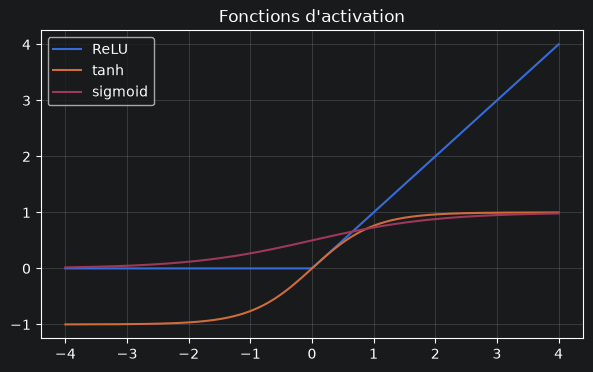

In [9]:
x = torch.linspace(-4, 4, 200)
relu = torch.relu(x)
tanh = torch.tanh(x)
sigmoid = torch.sigmoid(x)

plt.figure(figsize=(7, 4))
plt.plot(x.numpy(), relu.numpy(), label="ReLU")
plt.plot(x.numpy(), tanh.numpy(), label="tanh")
plt.plot(x.numpy(), sigmoid.numpy(), label="sigmoid")
plt.grid(True, alpha=0.3)
plt.legend()
plt.title("Fonctions d'activation")
plt.show()

## 6. Forward propagation

L'appel `model(X)` déclenche automatiquement `model.forward(X)`.

In [10]:
X = torch.randn(5, 4)
predicted = model(X)
print("Shape entrée :", X.shape)
print("Shape sortie :", predicted.shape)

Shape entrée : torch.Size([5, 4])
Shape sortie : torch.Size([5, 3])


## 7. Fonctions de coût

- régression : `nn.MSELoss()`
- classification multi-classe : `nn.CrossEntropyLoss()`
- classification binaire : `nn.BCEWithLogitsLoss()`

In [11]:
# Régression
criterion_reg = nn.MSELoss()
y_pred = torch.tensor([[2.0], [4.0]])
y_true = torch.tensor([[3.0], [5.0]])
print("MSE =", criterion_reg(y_pred, y_true).item())

# Classification multi-classe : logits (N, C) et étiquettes entières (N,)
criterion_cls = nn.CrossEntropyLoss()
pred = torch.tensor([[2.0, 1.0, 0.5], [0.2, 0.1, 2.0]])
y = torch.tensor([0, 2])
print("CrossEntropy =", criterion_cls(pred, y).item())

# Classification binaire : un logit par exemple, étiquettes en float
criterion_bin = nn.BCEWithLogitsLoss()
logits_bin = torch.tensor([[0.8], [-1.2]])
y_bin = torch.tensor([[1.0], [0.0]])
print("BCEWithLogits =", criterion_bin(logits_bin, y_bin).item())

MSE = 1.0
CrossEntropy = 0.36905235052108765
BCEWithLogits = 0.31719154119491577


## 8. Optimizers

L'optimiseur utilise les gradients pour mettre à jour les paramètres.

In [12]:
simple_model = nn.Linear(1, 1)
optimizer = torch.optim.Adam(simple_model.parameters(), lr=1e-2)
print(optimizer)

# Un pas de SGD à la main pour voir l'effet : w <- w - lr * dL/dw
m = nn.Linear(1, 1)
opt_sgd = torch.optim.SGD(m.parameters(), lr=0.1)
x_t, y_t = torch.tensor([[1.0]]), torch.tensor([[5.0]])

print("\nw avant :", m.weight.item())
loss = nn.MSELoss()(m(x_t), y_t)
opt_sgd.zero_grad()
loss.backward()
opt_sgd.step()
print("w après :", m.weight.item())

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    weight_decay: 0
)

w avant : -0.12794113159179688
w après : 0.7076231241226196


## 9. La boucle d'apprentissage

C'est le cœur de PyTorch. Ici on apprend $y = 2x + 1$ sur 8 points.

In [13]:
X = torch.randn(8, 1)
y = 2 * X + 1

simple_model = nn.Linear(1, 1)
optimizer = torch.optim.Adam(simple_model.parameters(), lr=1e-2)
criterion = nn.MSELoss()
epochs = 500

for epoch in range(epochs):
    simple_model.train()
    y_pred = simple_model(X)
    loss = criterion(y_pred, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if epoch % 100 == 0:
        print(f"epoch={epoch} loss={loss.item():.4f}")

print("w =", simple_model.weight.item(), "| b =", simple_model.bias.item(), "(cibles : 2 et 1)")

epoch=0 loss=4.5863
epoch=100 loss=1.0981
epoch=200 loss=0.3458
epoch=300 loss=0.0989
epoch=400 loss=0.0218
w = 1.9216110706329346 | b = 1.0389184951782227 (cibles : 2 et 1)


## 10. `train()` et `eval()`

`model.train()` et `model.eval()` changent le comportement de `Dropout` et `BatchNorm`.
`eval()` ne désactive pas le calcul des gradients : pour l'inférence on ajoute `torch.inference_mode()`.

In [14]:
class DropoutDemo(nn.Module):
    def __init__(self):
        super().__init__()
        self.dropout = nn.Dropout(p=0.5)

    def forward(self, x):
        return self.dropout(x)

m = DropoutDemo()
x = torch.ones(10)

m.train()
print("train() :", m(x))        # une partie des valeurs est mise à 0, les autres sont multipliées par 2

m.eval()
with torch.inference_mode():
    print("eval()  :", m(x))    # aucune valeur supprimée

train() : tensor([0., 2., 0., 0., 0., 2., 2., 2., 2., 0.])
eval()  : tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])


## 11. `Dataset` et `DataLoader`

In [15]:
X = torch.randn(100, 3)
y = torch.randn(100, 1)

dataset = TensorDataset(X, y)
loader = DataLoader(dataset, batch_size=16, shuffle=True)

print("taille du dataset :", len(dataset))
print("nombre de batchs  :", len(loader))      # 100 / 16 -> 7 batchs (le dernier a 4 éléments)

for X_batch, y_batch in loader:
    print("Batch X :", X_batch.shape, "| Batch y :", y_batch.shape)
    break

taille du dataset : 100
nombre de batchs  : 7
Batch X : torch.Size([16, 3]) | Batch y : torch.Size([16, 1])


# Partie pratique 1 : régression linéaire

On génère des données proches de $y = 3x + 2 + \text{bruit}$.

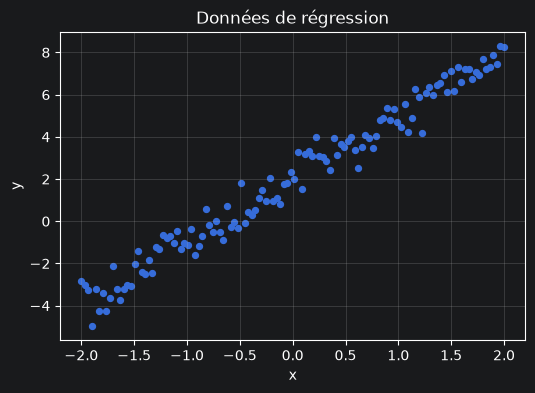

In [16]:
torch.manual_seed(42)

X = torch.linspace(-2, 2, 120).unsqueeze(1)
noise = 0.6 * torch.randn_like(X)
y = 3 * X + 2 + noise

plt.figure(figsize=(6, 4))
plt.scatter(X.numpy(), y.numpy(), s=18)
plt.title("Données de régression")
plt.xlabel("x"); plt.ylabel("y")
plt.grid(True, alpha=0.3)
plt.show()

## 12. Modèle, loss et optimizer

In [17]:
model_reg = nn.Linear(1, 1).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model_reg.parameters(), lr=0.05)

# Données sur le même device que le modèle
X_d, y_d = X.to(device), y.to(device)

## 13. Entraînement de la régression

In [18]:
losses = []

for epoch in range(300):
    model_reg.train()

    y_pred = model_reg(X_d)              # forward
    loss = criterion(y_pred, y_d)        # loss

    optimizer.zero_grad()                # remise à zéro des gradients
    loss.backward()                      # backward
    optimizer.step()                     # mise à jour des paramètres

    losses.append(loss.item())
    if (epoch + 1) % 50 == 0:
        print(f"epoch {epoch + 1:3d} | loss = {loss.item():.4f}")

print(f"\nw appris = {model_reg.weight.item():.3f} (cible 3)")
print(f"b appris = {model_reg.bias.item():.3f} (cible 2)")

epoch  50 | loss = 4.6846
epoch 100 | loss = 0.5542
epoch 150 | loss = 0.3463
epoch 200 | loss = 0.3438
epoch 250 | loss = 0.3438
epoch 300 | loss = 0.3438

w appris = 2.989 (cible 3)
b appris = 2.030 (cible 2)


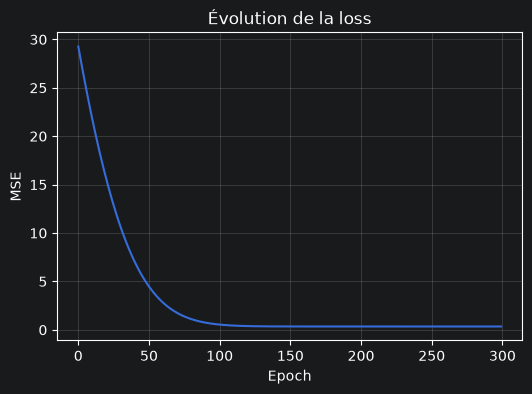

In [19]:
plt.figure(figsize=(6, 4))
plt.plot(losses)
plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.title("Évolution de la loss")
plt.grid(True, alpha=0.3)
plt.show()

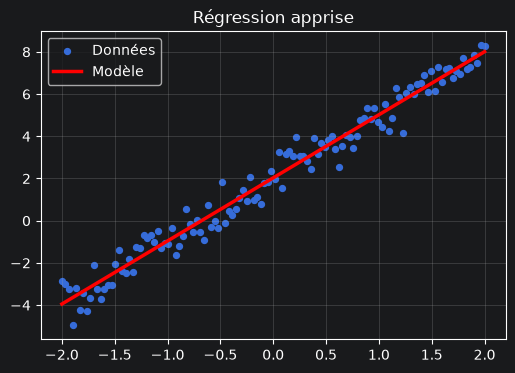

In [20]:
model_reg.eval()
with torch.inference_mode():
    y_hat = model_reg(X_d).cpu()

plt.figure(figsize=(6, 4))
plt.scatter(X.numpy(), y.numpy(), s=18, label="Données")
plt.plot(X.numpy(), y_hat.numpy(), color="red", linewidth=2.5, label="Modèle")
plt.legend(); plt.title("Régression apprise")
plt.grid(True, alpha=0.3)
plt.show()

In [21]:
from torcheval.metrics import R2Score

metric = R2Score()
metric.update(y_hat, y)
r2 = metric.compute()
print(f"R2 Score = {r2:.3f}")

R2 Score = 0.972


# Partie pratique 2 : classification

Deux classes de points en 2D.

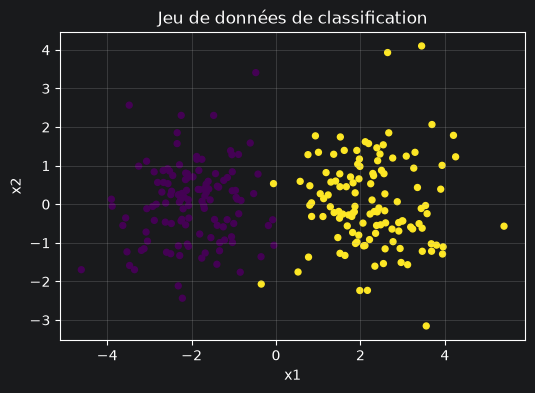

In [22]:
torch.manual_seed(0)

n = 120
class0 = torch.randn(n, 2) + torch.tensor([-2.0, 0.0])
class1 = torch.randn(n, 2) + torch.tensor([ 2.0, 0.0])

X_cls = torch.cat([class0, class1], dim=0)
y_cls = torch.cat([
    torch.zeros(n, dtype=torch.long),
    torch.ones(n, dtype=torch.long),
])

plt.figure(figsize=(6, 4))
plt.scatter(X_cls[:, 0], X_cls[:, 1], c=y_cls, s=18)
plt.title("Jeu de données de classification")
plt.xlabel("x1"); plt.ylabel("x2")
plt.grid(True, alpha=0.3)
plt.show()

## 14. Modèle de classification

Le réseau sort des **logits** (scores bruts), sans Softmax : `CrossEntropyLoss` l'applique en interne.
Les étiquettes sont des entiers (`torch.long`).

In [23]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 16),
            nn.ReLU(),
            nn.Linear(16, 16),
            nn.ReLU(),
            nn.Linear(16, 2),            # 2 classes -> 2 logits
        )

    def forward(self, x):
        return self.net(x)

model_cls = Classifier().to(device)
criterion_cls = nn.CrossEntropyLoss()
optimizer_cls = torch.optim.Adam(model_cls.parameters(), lr=0.01)

Xc, yc = X_cls.to(device), y_cls.to(device)

## 15. Entraînement de la classification

epoch  50 | loss = 0.0110
epoch 100 | loss = 0.0052
epoch 150 | loss = 0.0024
epoch 200 | loss = 0.0012
epoch 250 | loss = 0.0007


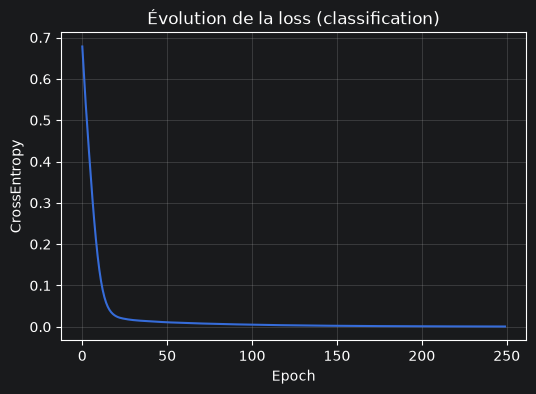

In [24]:
losses_cls = []

for epoch in range(250):
    model_cls.train()

    logits = model_cls(Xc)
    loss = criterion_cls(logits, yc)

    optimizer_cls.zero_grad()
    loss.backward()
    optimizer_cls.step()

    losses_cls.append(loss.item())
    if (epoch + 1) % 50 == 0:
        print(f"epoch {epoch + 1:3d} | loss = {loss.item():.4f}")

plt.figure(figsize=(6, 4))
plt.plot(losses_cls)
plt.xlabel("Epoch"); plt.ylabel("CrossEntropy"); plt.title("Évolution de la loss (classification)")
plt.grid(True, alpha=0.3)
plt.show()

In [25]:
model_cls.eval()
with torch.inference_mode():
    logits = model_cls(Xc)
    pred = logits.argmax(dim=1)          # classe au score maximal
    accuracy = (pred == yc).float().mean()

print(f"Accuracy = {accuracy.item() * 100:.2f}%")

Accuracy = 100.00%


### Métriques de classification avec `torcheval`

Pour toutes les métriques, l'ordre des arguments est `update(prédictions, vraies étiquettes)`.

Accuracy = 1.0000, recall = 1.0000, precision = 1.0000, f1 = 1.0000
tensor([[120.,   0.],
        [  0., 120.]])


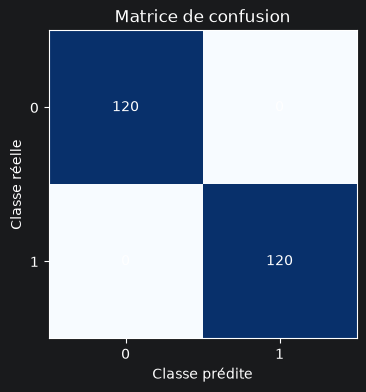

In [26]:
from torcheval.metrics import (BinaryAccuracy, BinaryRecall, BinaryPrecision,
                               BinaryF1Score, BinaryConfusionMatrix)

pred_c, y_c = pred.cpu(), y_cls

accuracy_metric = BinaryAccuracy()
accuracy_metric.update(pred_c, y_c)

recall_metric = BinaryRecall()
recall_metric.update(pred_c, y_c)

precision_metric = BinaryPrecision()
precision_metric.update(pred_c, y_c)

f1_metric = BinaryF1Score()
f1_metric.update(pred_c, y_c)

print(f"Accuracy = {accuracy_metric.compute():.4f}, "
      f"recall = {recall_metric.compute():.4f}, "
      f"precision = {precision_metric.compute():.4f}, "
      f"f1 = {f1_metric.compute():.4f}")

# Matrice de confusion : lignes = classe réelle, colonnes = classe prédite
cm_metric = BinaryConfusionMatrix()
cm_metric.update(pred_c, y_c)
cm = cm_metric.compute()
print(cm)

plt.figure(figsize=(4, 4))
plt.imshow(cm.numpy(), cmap="Blues")
for i in range(2):
    for j in range(2):
        plt.text(j, i, int(cm[i, j]), ha="center", va="center")
plt.xticks([0, 1]); plt.yticks([0, 1])
plt.xlabel("Classe prédite"); plt.ylabel("Classe réelle")
plt.title("Matrice de confusion")
plt.show()

## Visualisation de la frontière de décision

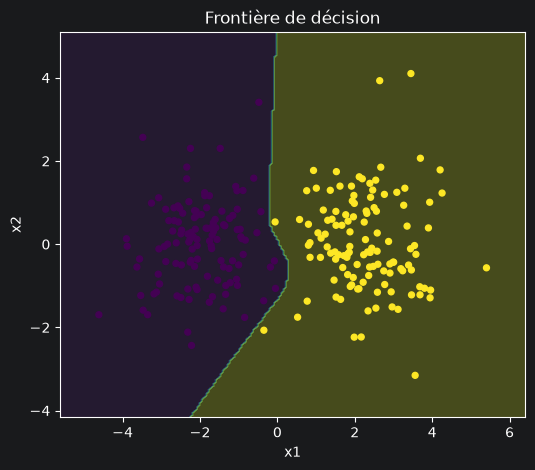

In [27]:
x1_min, x1_max = X_cls[:, 0].min() - 1, X_cls[:, 0].max() + 1
x2_min, x2_max = X_cls[:, 1].min() - 1, X_cls[:, 1].max() + 1

xx1, xx2 = torch.meshgrid(
    torch.linspace(x1_min, x1_max, 200),
    torch.linspace(x2_min, x2_max, 200),
    indexing="ij",
)

grid = torch.stack([xx1.reshape(-1), xx2.reshape(-1)], dim=1).to(device)

model_cls.eval()
with torch.inference_mode():
    zz = model_cls(grid).argmax(dim=1).reshape(xx1.shape).cpu()

plt.figure(figsize=(6, 5))
plt.contourf(xx1.numpy(), xx2.numpy(), zz.numpy(), alpha=0.25)
plt.scatter(X_cls[:, 0], X_cls[:, 1], c=y_cls, s=18)
plt.title("Frontière de décision")
plt.xlabel("x1"); plt.ylabel("x2")
plt.show()

## 16. Sauvegarder et recharger un modèle

In [28]:
path = "classifier_state_dict.pt"
torch.save(model_cls.state_dict(), path)      # on sauvegarde les paramètres, pas la classe
print("Modèle sauvegardé dans", path)

# Pour recharger : recréer la même architecture, puis charger les poids
new_model = Classifier().to(device)
new_model.load_state_dict(torch.load(path, weights_only=True))
new_model.eval()

with torch.inference_mode():
    pred_new = new_model(Xc).argmax(dim=1)

print("Prédictions identiques :", torch.equal(pred, pred_new))

Modèle sauvegardé dans classifier_state_dict.pt
Prédictions identiques : True


# Synthèse

Les briques essentielles de PyTorch sont en place :

1. `Tensor`
2. `nn.Module`
3. `forward()`
4. fonction de coût
5. `optimizer.zero_grad()`
6. `loss.backward()`
7. `optimizer.step()`
8. `train()` / `eval()`
9. `Dataset` / `DataLoader`
10. sauvegarde avec `state_dict()`

Cette mécanique reste la même pour des modèles plus avancés : CNN, Transformers, modèles génératifs ou PINNs.

# Exercice 1 : prédire le salaire à partir de l'ancienneté et de l'expertise

Régression linéaire multiple : `Salaire = w1 * Ancienneté + w2 * Expertise + b`.

In [29]:
# Génération des données : salaire = 4000 + 600*anciennete + 1500*expertise + bruit
n = 300
anciennete = torch.randint(0, 21, (n, 1)).float()    # 0 à 20 ans
expertise = torch.randint(1, 6, (n, 1)).float()      # note de 1 à 5
bruit = torch.randn(n, 1) * 500                      # écart-type de 500 DH

salaires = 4000 + 600 * anciennete + 1500 * expertise + bruit

X = torch.cat([anciennete, expertise], dim=1)        # (300, 2)
y = salaires                                         # (300, 1)

for i in range(5):
    print(f"Ancienneté : {X[i, 0].item():.0f} ans | "
          f"Expertise : {X[i, 1].item():.0f}/5 | "
          f"Salaire : {y[i, 0].item():.2f} DH")

Ancienneté : 8 ans | Expertise : 2/5 | Salaire : 11809.64 DH
Ancienneté : 12 ans | Expertise : 4/5 | Salaire : 17147.78 DH
Ancienneté : 9 ans | Expertise : 1/5 | Salaire : 10612.91 DH
Ancienneté : 12 ans | Expertise : 5/5 | Salaire : 17634.69 DH
Ancienneté : 16 ans | Expertise : 5/5 | Salaire : 20147.40 DH


## 1. Explorer les données

Dimensions de X : torch.Size([300, 2])
Dimensions de y : torch.Size([300, 1])
Salaire moyen   : 14711.31 DH


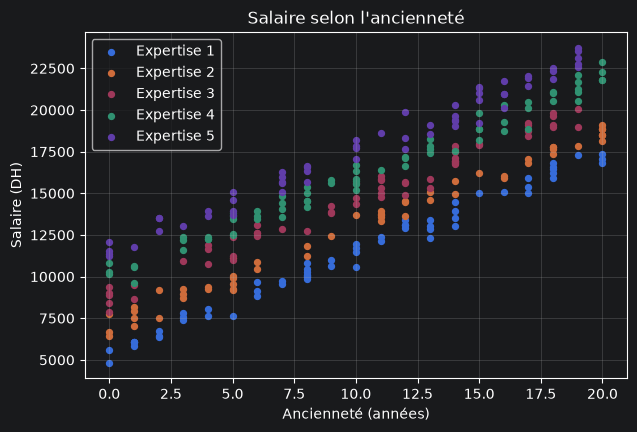

In [30]:
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)
print(f"Salaire moyen   : {y.mean().item():.2f} DH")

# Nuage de points : une couleur par niveau d'expertise
plt.figure(figsize=(7, 4.5))
for niveau in range(1, 6):
    masque = (X[:, 1] == niveau)
    plt.scatter(X[masque, 0], y[masque, 0], s=18, label=f"Expertise {niveau}")
plt.xlabel("Ancienneté (années)")
plt.ylabel("Salaire (DH)")
plt.title("Salaire selon l'ancienneté")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 2. Séparer et préparer les données

80 % pour l'entraînement, 20 % pour le test. Les entrées sont standardisées avec la moyenne et l'écart-type
du jeu d'entraînement uniquement, et les salaires sont exprimés en milliers de DH.

In [31]:
indices = torch.randperm(n)
limite = int(0.8 * n)
train_indices = indices[:limite]
test_indices = indices[limite:]

X_train, X_test = X[train_indices], X[test_indices]
y_train = y[train_indices] / 1000      # milliers de DH
y_test = y[test_indices] / 1000

# Statistiques calculées sur l'entraînement seulement, pour éviter toute fuite d'information du test
moyenne = X_train.mean(dim=0, keepdim=True)
ecart_type = X_train.std(dim=0, keepdim=True)

X_train_norm = (X_train - moyenne) / ecart_type
X_test_norm = (X_test - moyenne) / ecart_type

print("Train :", X_train_norm.shape, "| Test :", X_test_norm.shape)
print("Moyenne des entrées normalisées (train) :", X_train_norm.mean(dim=0))
print("Écart-type des entrées normalisées (train) :", X_train_norm.std(dim=0))

# Tout sur le même device que le modèle
X_train_norm, X_test_norm = X_train_norm.to(device), X_test_norm.to(device)
y_train, y_test = y_train.to(device), y_test.to(device)

Train : torch.Size([240, 2]) | Test : torch.Size([60, 2])
Moyenne des entrées normalisées (train) : tensor([-4.3710e-08,  7.6493e-08])
Écart-type des entrées normalisées (train) : tensor([1., 1.])


## 3. Modèle, loss, optimizer et entraînement

In [32]:
# 2 entrées (ancienneté, expertise) -> 1 sortie (salaire)
model = nn.Linear(2, 1).to(device)

criterion = nn.MSELoss()
# Les salaires tournent autour de 15 (en milliers de DH) et le biais part de 0 :
# avec Adam, lr=0.05 est trop lent pour 500 époques, 0.1 converge
optimizer = torch.optim.Adam(model.parameters(), lr=0.1)

historique = []

model.train()
for epoch in range(500):
    optimizer.zero_grad()                       # 1. remise à zéro des gradients
    predictions = model(X_train_norm)           # 2. prédictions
    loss = criterion(predictions, y_train)      # 3. perte
    loss.backward()                             # 4. gradients
    optimizer.step()                            # 5. mise à jour des paramètres

    historique.append(loss.item())

    if (epoch + 1) % 100 == 0:
        print(f"Époque {epoch + 1} | Perte : {loss.item():.4f}")

Époque 100 | Perte : 38.5209
Époque 200 | Perte : 3.1837
Époque 300 | Perte : 0.3322
Époque 400 | Perte : 0.2454
Époque 500 | Perte : 0.2444


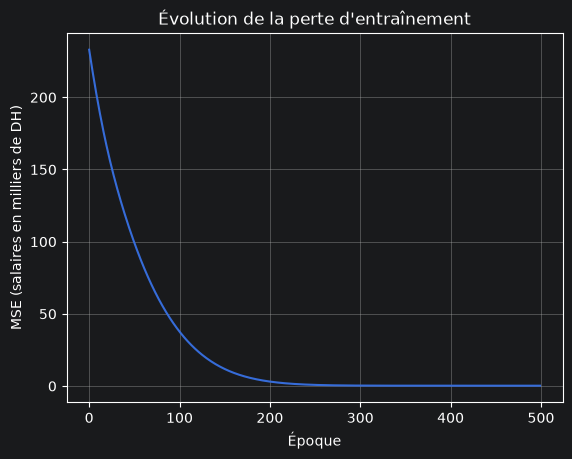

In [33]:
plt.plot(historique)
plt.xlabel("Époque")
plt.ylabel("MSE (salaires en milliers de DH)")
plt.title("Évolution de la perte d'entraînement")
plt.grid()
plt.show()

## 4. Évaluer sur le jeu de test

MAE en DH, plus RMSE et $R^2$ pour situer l'erreur par rapport à la variance des salaires.

In [34]:
model.eval()

with torch.inference_mode():
    predictions_test = model(X_test_norm)

    # Conversion en DH
    predictions_dh = predictions_test * 1000
    salaires_reels_dh = y_test * 1000

    mae = (predictions_dh - salaires_reels_dh).abs().mean()
    rmse = ((predictions_dh - salaires_reels_dh) ** 2).mean().sqrt()

metric = R2Score()
metric.update(predictions_dh.cpu(), salaires_reels_dh.cpu())
r2 = metric.compute()

print(f"Erreur absolue moyenne : {mae.item():.2f} DH")
print(f"RMSE                   : {rmse.item():.2f} DH")
print(f"R2                     : {r2.item():.3f}")

Erreur absolue moyenne : 358.91 DH
RMSE                   : 424.67 DH
R2                     : 0.989


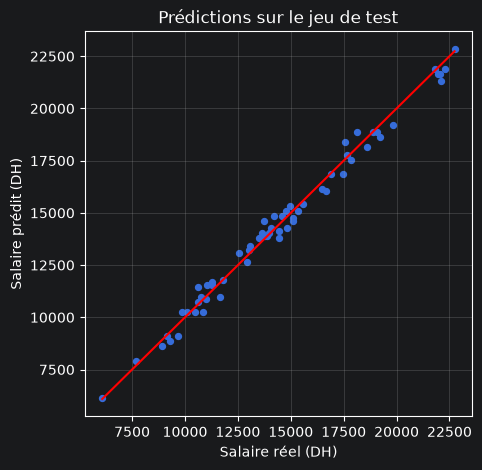

In [35]:
# Prédictions contre valeurs réelles : les points doivent suivre la diagonale
plt.figure(figsize=(5, 5))
plt.scatter(salaires_reels_dh.cpu(), predictions_dh.cpu(), s=18)
lim = [salaires_reels_dh.min().item(), salaires_reels_dh.max().item()]
plt.plot(lim, lim, color="red")
plt.xlabel("Salaire réel (DH)")
plt.ylabel("Salaire prédit (DH)")
plt.title("Prédictions sur le jeu de test")
plt.grid(True, alpha=0.3)
plt.show()

## 5. Prédire le salaire de nouveaux profils

In [36]:
nouveau_salarie = torch.tensor([[7.0, 4.0]])      # 7 ans d'ancienneté, expertise 4/5

# Même normalisation qu'à l'entraînement (moyenne et écart-type du train)
nouveau_salarie_norm = ((nouveau_salarie - moyenne) / ecart_type).to(device)

with torch.inference_mode():
    salaire_predit = model(nouveau_salarie_norm) * 1000     # retour en DH

print(f"Salaire estimé : {salaire_predit.item():.2f} DH")
print("Valeur théorique sans bruit : 14200 DH")

# Quelques autres profils
profils = torch.tensor([[0.0, 1.0], [5.0, 3.0], [15.0, 5.0], [20.0, 2.0]])
profils_norm = ((profils - moyenne) / ecart_type).to(device)
with torch.inference_mode():
    estimations = model(profils_norm).squeeze(1) * 1000

for (anc, exp), est in zip(profils.tolist(), estimations.tolist()):
    theorique = 4000 + 600 * anc + 1500 * exp
    print(f"Ancienneté {anc:4.0f} ans | Expertise {exp:.0f}/5 | estimé : {est:9.2f} DH | théorique : {theorique:9.0f} DH")

Salaire estimé : 14262.85 DH
Valeur théorique sans bruit : 14200 DH
Ancienneté    0 ans | Expertise 1/5 | estimé :   5570.74 DH | théorique :      5500 DH
Ancienneté    5 ans | Expertise 3/5 | estimé :  11561.57 DH | théorique :     11500 DH
Ancienneté   15 ans | Expertise 5/5 | estimé :  20493.70 DH | théorique :     20500 DH
Ancienneté   20 ans | Expertise 2/5 | estimé :  18860.71 DH | théorique :     19000 DH


## Retrouver les coefficients en unités d'origine

Le modèle apprend sur des entrées standardisées et des salaires en milliers de DH :
`y/1000 = w1 * (anc - m1)/s1 + w2 * (exp - m2)/s2 + b`.
En développant, le coefficient d'origine de chaque variable vaut `1000 * w_i / s_i`,
et l'ordonnée à l'origine vaut `1000 * (b - w1*m1/s1 - w2*m2/s2)`.

In [37]:
w = model.weight.detach().cpu()          # (1, 2)
b = model.bias.detach().cpu()            # (1,)
m = moyenne.cpu()
s = ecart_type.cpu()

coef_origine = 1000 * w / s                              # DH par unité de chaque variable
intercept_origine = 1000 * (b - (w * m / s).sum())       # DH

print(f"Ancienneté : {coef_origine[0, 0].item():.1f} DH par année (cible 600)")
print(f"Expertise  : {coef_origine[0, 1].item():.1f} DH par niveau (cible 1500)")
print(f"Constante  : {intercept_origine.item():.1f} DH (cible 4000)")

Ancienneté : 588.3 DH par année (cible 600)
Expertise  : 1524.8 DH par niveau (cible 1500)
Constante  : 4046.0 DH (cible 4000)


## Questions complémentaires

**À expertise constante, quel est l'effet d'une année d'ancienneté supplémentaire ?**
Le salaire augmente d'environ 600 DH par mois, c'est le coefficient de l'ancienneté retrouvé en unités d'origine.

**Pourquoi la perte ne devient-elle pas exactement nulle ?**
Le bruit (écart-type de 500 DH) ne dépend ni de l'ancienneté ni de l'expertise, donc le modèle ne peut pas l'expliquer.
En milliers de DH la MSE ne descend pas sous la variance du bruit, soit environ 0.25.

**Le modèle est-il fiable pour une ancienneté de 40 ans ?**
Non. Les données s'arrêtent à 20 ans, donc c'est de l'extrapolation. Le modèle prolonge la droite sans rien pour vérifier
que la relation reste linéaire au-delà (plafonnement des salaires, grilles, etc.).

**Quel effet aurait une augmentation du bruit sur la précision ?**
La MAE, la RMSE et la perte augmentent, et le $R^2$ baisse. Les coefficients restent en moyenne proches de 600, 1500 et 4000,
mais ils varient davantage d'un tirage à l'autre.

**Remarque sur l'expertise.**
La traiter comme un nombre suppose que passer de 1 à 2 vaut autant que passer de 4 à 5. C'est vrai ici parce que les données
sont générées ainsi, il faudrait le vérifier sur des données réelles.

# Exercice 2 : classification des fleurs Iris

## 1. Préparation des données

In [39]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torcheval.metrics import (MulticlassAccuracy, MulticlassPrecision,
                               MulticlassRecall, MulticlassF1Score,
                               MulticlassConfusionMatrix)

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Charger les données
iris = load_iris()
X, y = iris.data, iris.target
print("Features :", iris.feature_names)
print("Classes  :", [str(n) for n in iris.target_names])

# Séparer les données : 80 % entraînement, 20 % test (même proportion de chaque espèce)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Ajuster la normalisation uniquement sur l'entraînement
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convertir en tenseurs, directement sur le device
X_train = torch.tensor(X_train, dtype=torch.float32).to(device)
X_test = torch.tensor(X_test, dtype=torch.float32).to(device)
y_train = torch.tensor(y_train, dtype=torch.long).to(device)
y_test = torch.tensor(y_test, dtype=torch.long).to(device)

print("\nDimensions :", X_train.shape, y_train.shape, "|", X_test.shape, y_test.shape)

Features : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes  : ['setosa', 'versicolor', 'virginica']

Dimensions : torch.Size([120, 4]) torch.Size([120]) | torch.Size([30, 4]) torch.Size([30])


**Que représentent les quatre colonnes de `X_train` ?**
La longueur et la largeur des sépales, puis la longueur et la largeur des pétales, en cm. Elles sont standardisées
(moyenne 0, écart-type 1 sur l'entraînement), donc ce ne sont plus des centimètres.

**Pourquoi `torch.long` pour les étiquettes ?**
`CrossEntropyLoss` attend des indices de classe (0, 1 ou 2) en entiers 64 bits. Elle s'en sert pour aller chercher
le score de la bonne classe dans les logits.

**Pourquoi ne pas ajuster le `StandardScaler` sur le test ?**
Le test doit jouer le rôle de données jamais vues. Si le scaler utilise leur moyenne et leur écart-type, des informations
du test fuitent dans la préparation et l'évaluation devient trop optimiste.

## 2. Construire le réseau

4 entrées, une couche cachée de 16 neurones, 3 sorties (une par espèce). Pas de Softmax en sortie :
`CrossEntropyLoss` attend les logits.

In [40]:
model = nn.Sequential(
    nn.Linear(4, 16),
    nn.ReLU(),
    nn.Linear(16, 3)
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

print(model)

Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=3, bias=True)
)


## 3. Entraîner le modèle

Chaque itération utilise toutes les données d'entraînement.

In [41]:
epochs = 200
losses = []

model.train()

for epoch in range(epochs):
    optimizer.zero_grad()                 # remettre les gradients à zéro
    logits = model(X_train)               # scores prédits
    loss = criterion(logits, y_train)     # perte
    loss.backward()                       # gradients
    optimizer.step()                      # mise à jour des paramètres

    losses.append(loss.item())

    if (epoch + 1) % 20 == 0:
        print(f"Époque {epoch + 1:3d} | Perte : {loss.item():.4f}")

Époque  20 | Perte : 0.3695
Époque  40 | Perte : 0.1923
Époque  60 | Perte : 0.1063
Époque  80 | Perte : 0.0724
Époque 100 | Perte : 0.0590
Époque 120 | Perte : 0.0525
Époque 140 | Perte : 0.0488
Époque 160 | Perte : 0.0463
Époque 180 | Perte : 0.0445
Époque 200 | Perte : 0.0432


## 4. Évaluer le classifieur

In [42]:
model.eval()

with torch.inference_mode():
    logits = model(X_test)

    # Classe au score maximal pour chaque fleur
    predictions = logits.argmax(dim=1)

    # Proportion de prédictions correctes
    accuracy = (predictions == y_test).float().mean()

print(f"Accuracy sur le test : {accuracy.item():.1%}")

Accuracy sur le test : 100.0%


### Métriques détaillées

Trois classes, donc on utilise les versions multiclasses de `torcheval`. L'ordre des arguments est
`update(prédictions, vraies étiquettes)`. Les moyennes sont en `macro` : chaque classe compte autant, quelle que soit sa taille.

In [43]:
preds_cpu, y_test_cpu = predictions.cpu(), y_test.cpu()

accuracy_m = MulticlassAccuracy(num_classes=3)
precision_m = MulticlassPrecision(num_classes=3, average="macro")
recall_m = MulticlassRecall(num_classes=3, average="macro")
f1_m = MulticlassF1Score(num_classes=3, average="macro")

for m in (accuracy_m, precision_m, recall_m, f1_m):
    m.update(preds_cpu, y_test_cpu)

print(f"Accuracy  = {accuracy_m.compute():.4f}")
print(f"Precision = {precision_m.compute():.4f}")
print(f"Recall    = {recall_m.compute():.4f}")
print(f"F1-score  = {f1_m.compute():.4f}")

Accuracy  = 1.0000
Precision = 1.0000
Recall    = 1.0000
F1-score  = 1.0000


## 5. Autres questions

### Courbe de perte

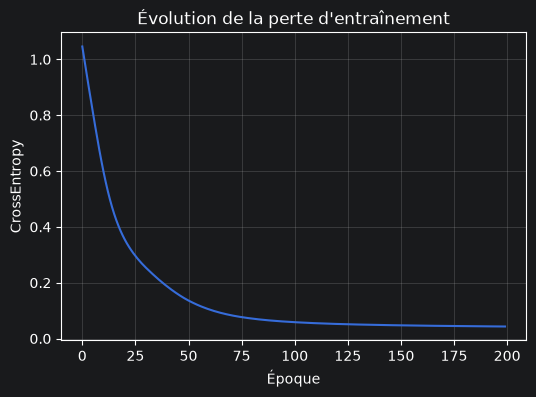

In [44]:
plt.figure(figsize=(6, 4))
plt.plot(losses)
plt.xlabel("Époque")
plt.ylabel("CrossEntropy")
plt.title("Évolution de la perte d'entraînement")
plt.grid(True, alpha=0.3)
plt.show()

### Matrice de confusion

Lignes : classe réelle. Colonnes : classe prédite.

tensor([[10.,  0.,  0.],
        [ 0., 10.,  0.],
        [ 0.,  0., 10.]])


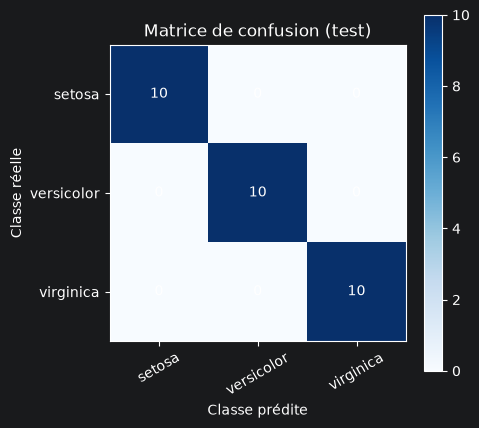

In [45]:
cm_metric = MulticlassConfusionMatrix(num_classes=3)
cm_metric.update(preds_cpu, y_test_cpu)
cm = cm_metric.compute()
print(cm)

noms = list(iris.target_names)

plt.figure(figsize=(5, 4.5))
plt.imshow(cm.numpy(), cmap="Blues")
plt.colorbar()
for i in range(3):
    for j in range(3):
        plt.text(j, i, int(cm[i, j]), ha="center", va="center")
plt.xticks(range(3), noms, rotation=30)
plt.yticks(range(3), noms)
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.title("Matrice de confusion (test)")
plt.tight_layout()
plt.show()

### Comparaison avec un modèle sans couche cachée : `nn.Linear(4, 3)`

On factorise l'entraînement dans une fonction pour entraîner les deux modèles exactement de la même façon.

Réseau avec couche cachée : perte finale = 0.0432 | accuracy test = 100.0%
nn.Linear(4, 3)           : perte finale = 0.2416 | accuracy test = 90.0%


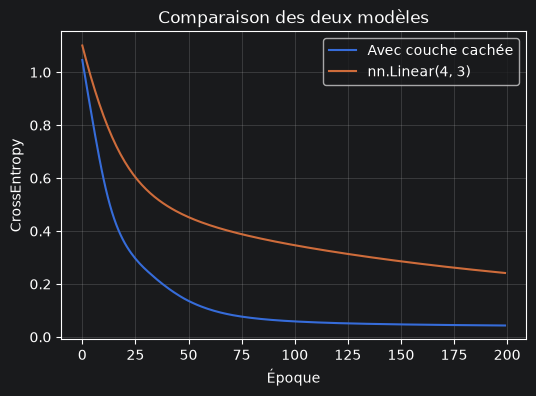

In [46]:
def entrainer(modele, epochs=200, lr=0.01):
    # Entraîne un modèle sur tout le jeu d'entraînement et renvoie l'historique de la perte
    modele.to(device)
    critere = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(modele.parameters(), lr=lr)
    historique = []

    modele.train()
    for _ in range(epochs):
        opt.zero_grad()
        perte = critere(modele(X_train), y_train)
        perte.backward()
        opt.step()
        historique.append(perte.item())
    return historique

def accuracy_test(modele):
    modele.eval()
    with torch.inference_mode():
        return (modele(X_test).argmax(dim=1) == y_test).float().mean().item()

torch.manual_seed(42)
model_lineaire = nn.Linear(4, 3)
losses_lineaire = entrainer(model_lineaire)

print(f"Réseau avec couche cachée : perte finale = {losses[-1]:.4f} | accuracy test = {accuracy_test(model):.1%}")
print(f"nn.Linear(4, 3)           : perte finale = {losses_lineaire[-1]:.4f} | accuracy test = {accuracy_test(model_lineaire):.1%}")

plt.figure(figsize=(6, 4))
plt.plot(losses, label="Avec couche cachée")
plt.plot(losses_lineaire, label="nn.Linear(4, 3)")
plt.xlabel("Époque"); plt.ylabel("CrossEntropy")
plt.title("Comparaison des deux modèles")
plt.legend(); plt.grid(True, alpha=0.3)
plt.show()

### Prédire l'espèce d'une nouvelle fleur

Mesures `[5.1, 3.5, 1.4, 0.2]`, normalisées avec le **même scaler** (celui ajusté sur l'entraînement).

In [47]:
nouvelle_fleur = [[5.1, 3.5, 1.4, 0.2]]

# transform seulement, jamais fit_transform
nouvelle_fleur_norm = torch.tensor(scaler.transform(nouvelle_fleur), dtype=torch.float32).to(device)

model.eval()
with torch.inference_mode():
    logits = model(nouvelle_fleur_norm)
    probabilites = torch.softmax(logits, dim=1)     # le Softmax sert ici seulement à lire les scores en probabilités
    classe = probabilites.argmax(dim=1).item()

print("Espèce prédite :", iris.target_names[classe])
for nom, p in zip(iris.target_names, probabilites[0].tolist()):
    print(f"  {nom:<11s} {p:.1%}")

Espèce prédite : setosa
  setosa      100.0%
  versicolor  0.0%
  virginica   0.0%


# Exercice 3 : classifier les chiffres MNIST avec un MLP

## 1. Chargement des données

In [48]:
from torchvision import datasets, transforms
from torcheval.metrics import (MulticlassAccuracy, MulticlassPrecision,MulticlassRecall, MulticlassF1Score, MulticlassConfusionMatrix)

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ToTensor : image 28x28 en [0, 255] -> tensor (1, 28, 28) en [0, 1]
# Normalize : centrage et réduction avec la moyenne et l'écart-type de MNIST
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

# Mini-lots : mélange à l'entraînement seulement
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

print("Images d'entraînement :", len(train_dataset), "| Images de test :", len(test_dataset))
print("Mini-lots d'entraînement :", len(train_loader), "| Mini-lots de test :", len(test_loader))

images, labels = next(iter(train_loader))
print("Un lot d'images :", images.shape)   # (64, 1, 28, 28)
print("Un lot d'étiquettes :", labels.shape, labels.dtype)

100%|██████████| 9.91M/9.91M [00:04<00:00, 2.18MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 209kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 1.68MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 16.5MB/s]

Images d'entraînement : 60000 | Images de test : 10000
Mini-lots d'entraînement : 938 | Mini-lots de test : 40
Un lot d'images : torch.Size([64, 1, 28, 28])
Un lot d'étiquettes : torch.Size([64]) torch.int64


## 2. Construire le MLP

Chaque image est aplatie en un vecteur de 784 valeurs (`nn.Flatten`), puis passe par une couche cachée de 128 neurones.
Pas de Softmax en sortie : `CrossEntropyLoss` attend les scores bruts (logits) et des étiquettes entières.

In [49]:
def creer_mlp():
    # 784 entrées -> 128 neurones cachés -> 10 sorties (une par chiffre)
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(28 * 28, 128),
        nn.ReLU(),
        nn.Linear(128, 10)
    )

model = creer_mlp().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print(model)
print("Nombre de paramètres :", sum(p.numel() for p in model.parameters()))

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=10, bias=True)
)
Nombre de paramètres : 101770


## 3. Entraînement sur 5 époques

In [50]:
epochs = 5
losses = []        # perte moyenne par époque

for epoch in range(epochs):
    model.train()
    total_loss = 0.0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()                  # remettre les gradients à zéro
        logits = model(images)                 # scores prédits (64, 10)
        loss = criterion(logits, labels)       # perte
        loss.backward()                        # gradients
        optimizer.step()                       # mise à jour des paramètres

        total_loss += loss.item() * images.size(0)   # perte du lot x taille du lot

    epoch_loss = total_loss / len(train_dataset)
    losses.append(epoch_loss)
    print(f"Époque {epoch + 1}/{epochs} | Perte : {epoch_loss:.4f}")

Époque 1/5 | Perte : 0.2555
Époque 2/5 | Perte : 0.1085
Époque 3/5 | Perte : 0.0759
Époque 4/5 | Perte : 0.0571
Époque 5/5 | Perte : 0.0467


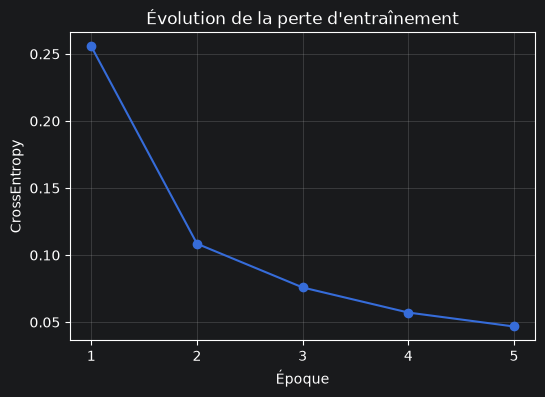

In [51]:
plt.figure(figsize=(6, 4))
plt.plot(range(1, epochs + 1), losses, marker="o")
plt.xlabel("Époque")
plt.ylabel("CrossEntropy")
plt.title("Évolution de la perte d'entraînement")
plt.xticks(range(1, epochs + 1))
plt.grid(True, alpha=0.3)
plt.show()

## 4. Évaluation sur le jeu de test

La fonction renvoie les classes prédites et les vraies classes pour tout le jeu de test.

In [52]:
def evaluer(modele):
    # Passe tout le jeu de test dans le modèle, sans calcul de gradients
    modele.eval()
    toutes_preds, tous_labels = [], []

    with torch.inference_mode():
        for images, labels in test_loader:
            images = images.to(device)
            outputs = modele(images)
            predicted_classes = outputs.argmax(dim=1)     # classe au score maximal

            toutes_preds.append(predicted_classes.cpu())
            tous_labels.append(labels)

    return torch.cat(toutes_preds), torch.cat(tous_labels)

preds, y_test = evaluer(model)

accuracy_brute = (preds == y_test).float().mean()
print(f"Accuracy sur le test : {accuracy_brute.item():.2%}")

Accuracy sur le test : 97.83%


### Métriques de classification

Dix classes, donc versions multiclasses de `torcheval`, avec `update(prédictions, vraies étiquettes)`.
Les moyennes sont en `macro` : chaque chiffre compte autant, quelle que soit sa fréquence.

In [53]:
accuracy_m = MulticlassAccuracy(num_classes=10)
precision_m = MulticlassPrecision(num_classes=10, average="macro")
recall_m = MulticlassRecall(num_classes=10, average="macro")
f1_m = MulticlassF1Score(num_classes=10, average="macro")

for m in (accuracy_m, precision_m, recall_m, f1_m):
    m.update(preds, y_test)

print(f"Accuracy  = {accuracy_m.compute():.4f}")
print(f"Precision = {precision_m.compute():.4f}")
print(f"Recall    = {recall_m.compute():.4f}")
print(f"F1-score  = {f1_m.compute():.4f}")

Accuracy  = 0.9783
Precision = 0.9780
Recall    = 0.9783
F1-score  = 0.9781


### Matrice de confusion

Lignes : chiffre réel. Colonnes : chiffre prédit. Tout ce qui est hors diagonale est une erreur.

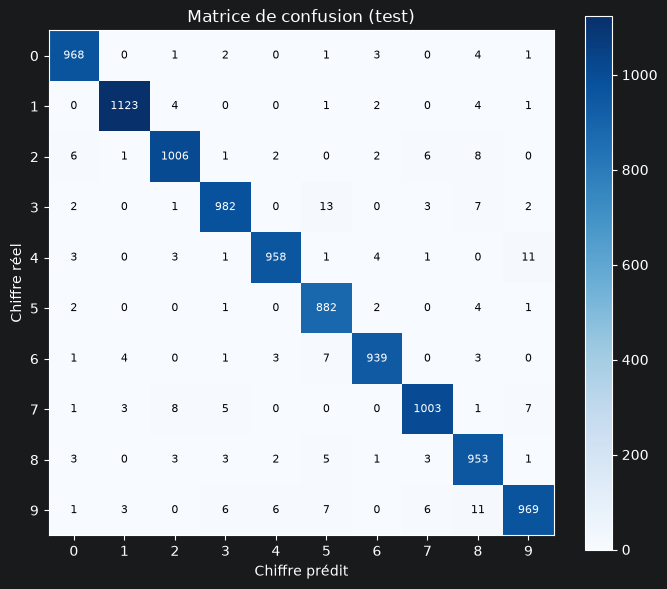

Confusions les plus fréquentes :
  3 pris pour 5 : 13 fois
  4 pris pour 9 : 11 fois
  9 pris pour 8 : 11 fois


In [54]:
cm_metric = MulticlassConfusionMatrix(num_classes=10)
cm_metric.update(preds, y_test)
cm = cm_metric.compute()

plt.figure(figsize=(7, 6))
plt.imshow(cm.numpy(), cmap="Blues")
plt.colorbar()
seuil = cm.max().item() / 2
for i in range(10):
    for j in range(10):
        plt.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=8,
                 color="white" if cm[i, j] > seuil else "black")
plt.xticks(range(10)); plt.yticks(range(10))
plt.xlabel("Chiffre prédit")
plt.ylabel("Chiffre réel")
plt.title("Matrice de confusion (test)")
plt.tight_layout()
plt.show()

# Les confusions les plus fréquentes (hors diagonale)
hors_diag = cm.clone()
hors_diag.fill_diagonal_(0)
top = torch.topk(hors_diag.flatten(), 3)
print("Confusions les plus fréquentes :")
for valeur, idx in zip(top.values, top.indices):
    if valeur > 0:
        reel, predit = divmod(idx.item(), 10)
        print(f"  {reel} pris pour {predit} : {int(valeur)} fois")

## 5. Images mal classées

Nombre d'images mal classées : 217 sur 10000


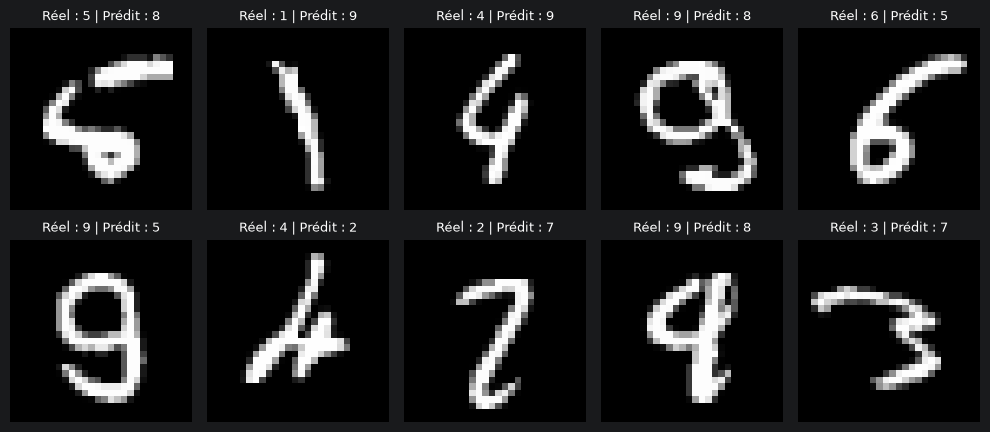

In [55]:
erreurs = (preds != y_test).nonzero(as_tuple=True)[0]
print(f"Nombre d'images mal classées : {len(erreurs)} sur {len(y_test)}")

n_images = min(10, len(erreurs))
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))

for ax, idx in zip(axes.flatten(), erreurs[:n_images].tolist()):
    image, label = test_dataset[idx]
    image = image[0] * 0.3081 + 0.1307          # annuler la normalisation pour l'affichage
    ax.imshow(image.numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Réel : {label} | Prédit : {preds[idx].item()}", fontsize=9)
    ax.axis("off")

# Masquer les cases vides s'il y a moins de 10 erreurs
for ax in axes.flatten()[n_images:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 6. Sauvegarder et recharger le modèle

On sauvegarde les paramètres (`state_dict`), pas la classe. Pour réutiliser le réseau sans réentraîner,
on recrée la même architecture puis on charge les poids.

In [56]:
path = "mnist_mlp.pth"
torch.save(model.state_dict(), path)
print("Modèle sauvegardé dans", path)

# Nouveau modèle : même architecture, poids initiaux aléatoires, puis chargement des poids sauvegardés
model_recharge = creer_mlp().to(device)
model_recharge.load_state_dict(torch.load(path, weights_only=True, map_location=device))

preds_recharge, _ = evaluer(model_recharge)

accuracy_recharge = (preds_recharge == y_test).float().mean()
print(f"Accuracy du modèle rechargé : {accuracy_recharge.item():.2%}")
print("Prédictions identiques :", torch.equal(preds, preds_recharge))

Modèle sauvegardé dans mnist_mlp.pth
Accuracy du modèle rechargé : 97.83%
Prédictions identiques : True


# Exercice 4 : classification MNIST avec un CNN

## 1. Chargement des données

In [57]:
import time
from torchvision import datasets, transforms

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil :", device)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

images, labels = next(iter(train_loader))

print("Images :", images.shape)   # [64, 1, 28, 28]
print("Labels :", labels.shape)   # [64]

Appareil : cpu
Images : torch.Size([64, 1, 28, 28])
Labels : torch.Size([64])


**Que représentent les quatre dimensions du tenseur `images` ?**
`[64, 1, 28, 28]` : 64 images dans le lot, 1 canal (niveaux de gris, il y en aurait 3 en couleur), 28 pixels de hauteur
et 28 pixels de largeur.

**Pourquoi mélanger les données d'entraînement avec `shuffle=True` ?**
Pour que les lots changent à chaque époque et que le modèle ne voie jamais les exemples dans le même ordre.
Sans mélange, des lots peuvent être dominés par un seul chiffre si les données sont triées, et les mises à jour des poids
deviennent biaisées. Au test, l'ordre n'a aucune importance, donc pas de mélange.

## 2. Visualiser quelques images

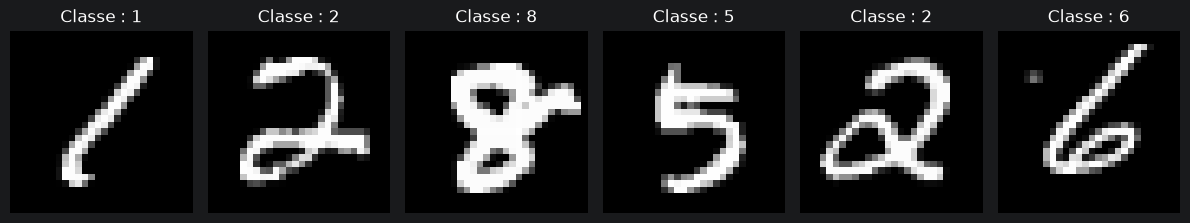

In [58]:
fig, axes = plt.subplots(1, 6, figsize=(12, 3))

for i, ax in enumerate(axes):
    # Annuler la normalisation pour l'affichage
    image = images[i, 0] * 0.3081 + 0.1307

    ax.imshow(image.numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Classe : {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 3. Construire le CNN

| Couche | Paramètres | Forme de sortie (hors lot) |
|---|---|---|
| Entrée | - | 1 × 28 × 28 |
| Convolution + ReLU | 16 filtres, noyau 3, padding 1 | 16 × 28 × 28 |
| Max pooling | noyau 2 | 16 × 14 × 14 |
| Convolution + ReLU | 32 filtres, noyau 3, padding 1 | 32 × 14 × 14 |
| Max pooling | noyau 2 | 32 × 7 × 7 |
| Flatten | - | 1568 |
| Linéaire + ReLU | 128 neurones | 128 |
| Linéaire | 10 classes | 10 |

Pas de Softmax : `CrossEntropyLoss` attend les logits. Le paramètre `dropout` (0 par défaut) sert plus loin
pour la question sur le Dropout.

In [59]:
class MNISTClassifier(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(p=dropout),        # sans effet quand dropout = 0
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)       # (N, 32, 7, 7)
        x = self.classifier(x)     # (N, 10)
        return x


model = MNISTClassifier().to(device)

# Vérifier la forme de sortie
with torch.inference_mode():
    output = model(images.to(device))

assert output.shape == (images.size(0), 10)
print("Sortie :", output.shape)
print("Nombre de paramètres :", sum(p.numel() for p in model.parameters()))

Sortie : torch.Size([64, 10])
Nombre de paramètres : 206922


In [60]:
# Suivre la forme du tenseur couche par couche
x = images[:1].to(device)
with torch.inference_mode():
    for couche in list(model.features) + list(model.classifier):
        x = couche(x)
        print(f"{couche.__class__.__name__:<10s} -> {tuple(x.shape)}")

Conv2d     -> (1, 16, 28, 28)
ReLU       -> (1, 16, 28, 28)
MaxPool2d  -> (1, 16, 14, 14)
Conv2d     -> (1, 32, 14, 14)
ReLU       -> (1, 32, 14, 14)
MaxPool2d  -> (1, 32, 7, 7)
Flatten    -> (1, 1568)
Linear     -> (1, 128)
ReLU       -> (1, 128)
Dropout    -> (1, 128)
Linear     -> (1, 10)


**Pourquoi la première couche linéaire reçoit-elle 32 × 7 × 7 valeurs ?**
Le `padding=1` avec un noyau 3 garde la taille 28 × 28 dans les convolutions, et chaque max pooling de noyau 2 divise la hauteur
et la largeur par 2 : 28 → 14 → 7. Après la deuxième convolution il y a 32 cartes de 7 × 7, que `Flatten` met bout à bout :
32 × 7 × 7 = 1568 valeurs par image.

## 4. Entraîner le réseau

Deux fonctions réutilisées pour tous les modèles de ce notebook : une pour l'entraînement, une pour l'évaluation.

In [61]:
def entrainer(modele, epochs=3, lr=0.001):
    # Entraîne un modèle sur le jeu d'entraînement et renvoie la perte moyenne de chaque époque
    modele.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(modele.parameters(), lr=lr)
    loss_history = []

    for epoch in range(epochs):
        modele.train()
        total_loss = 0.0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()                  # 1. réinitialiser les gradients
            logits = modele(images)                # 2. calculer les scores
            loss = criterion(logits, labels)       # 3. calculer la perte
            loss.backward()                        # 4. calculer les gradients
            optimizer.step()                       # 5. mettre à jour les paramètres

            total_loss += loss.item() * images.size(0)

        average_loss = total_loss / len(train_dataset)
        loss_history.append(average_loss)
        print(f"Époque {epoch + 1}/{epochs} | Perte : {average_loss:.4f}")

    return loss_history


def evaluer(modele):
    # Renvoie les classes prédites et les vraies classes sur tout le jeu de test
    modele.eval()
    toutes_preds, tous_labels = [], []

    with torch.inference_mode():
        for images, labels in test_loader:
            logits = modele(images.to(device))
            predictions = logits.argmax(dim=1)       # classe au score le plus élevé
            toutes_preds.append(predictions.cpu())
            tous_labels.append(labels)

    return torch.cat(toutes_preds), torch.cat(tous_labels)

In [62]:
epochs = 3

t0 = time.perf_counter()
loss_history = entrainer(model, epochs=epochs)
temps_cnn = time.perf_counter() - t0
print(f"Temps d'entraînement : {temps_cnn:.1f} s")

Époque 1/3 | Perte : 0.1679
Époque 2/3 | Perte : 0.0482
Époque 3/3 | Perte : 0.0348
Temps d'entraînement : 85.6 s


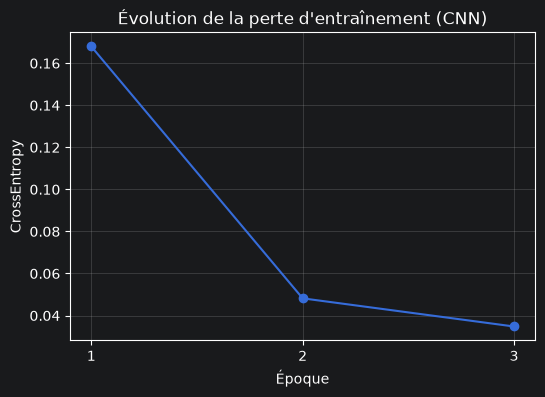

In [63]:
plt.figure(figsize=(6, 4))
plt.plot(range(1, epochs + 1), loss_history, marker="o")
plt.xlabel("Époque")
plt.ylabel("CrossEntropy")
plt.title("Évolution de la perte d'entraînement (CNN)")
plt.xticks(range(1, epochs + 1))
plt.grid(True, alpha=0.3)
plt.show()

## 5. Évaluer sur le jeu de test

In [64]:
preds, y_test = evaluer(model)

correct = (preds == y_test).sum().item()
total = y_test.size(0)
accuracy = correct / total
print(f"Accuracy sur le test : {accuracy:.2%}")

Accuracy sur le test : 98.88%


In [65]:
accuracy_m = MulticlassAccuracy(num_classes=10)
precision_m = MulticlassPrecision(num_classes=10, average="macro")
recall_m = MulticlassRecall(num_classes=10, average="macro")
f1_m = MulticlassF1Score(num_classes=10, average="macro")

for m in (accuracy_m, precision_m, recall_m, f1_m):
    m.update(preds, y_test)

print(f"Accuracy  = {accuracy_m.compute():.4f}")
print(f"Precision = {precision_m.compute():.4f}")
print(f"Recall    = {recall_m.compute():.4f}")
print(f"F1-score  = {f1_m.compute():.4f}")

Accuracy  = 0.9888
Precision = 0.9886
Recall    = 0.9888
F1-score  = 0.9887


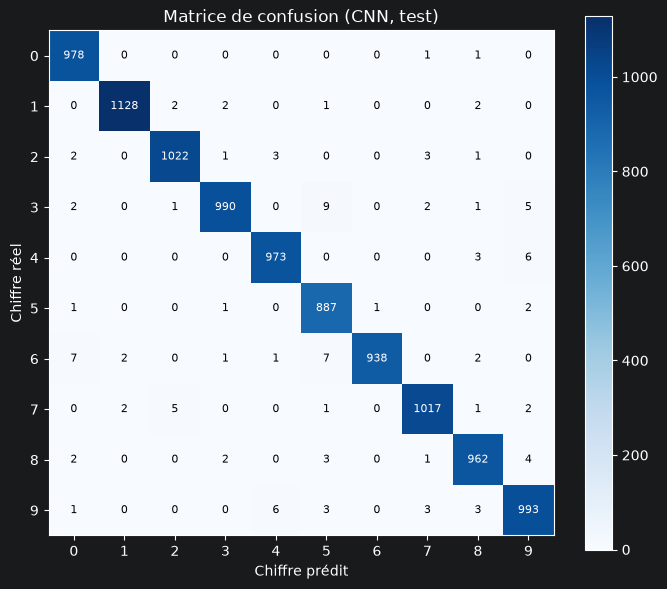

In [66]:
cm_metric = MulticlassConfusionMatrix(num_classes=10)
cm_metric.update(preds, y_test)
cm = cm_metric.compute()

plt.figure(figsize=(7, 6))
plt.imshow(cm.numpy(), cmap="Blues")
plt.colorbar()
seuil = cm.max().item() / 2
for i in range(10):
    for j in range(10):
        plt.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=8,
                 color="white" if cm[i, j] > seuil else "black")
plt.xticks(range(10)); plt.yticks(range(10))
plt.xlabel("Chiffre prédit")
plt.ylabel("Chiffre réel")
plt.title("Matrice de confusion (CNN, test)")
plt.tight_layout()
plt.show()

## 6. Autres questions

### Afficher 10 images mal classées

Nombre d'images mal classées : 112 sur 10000


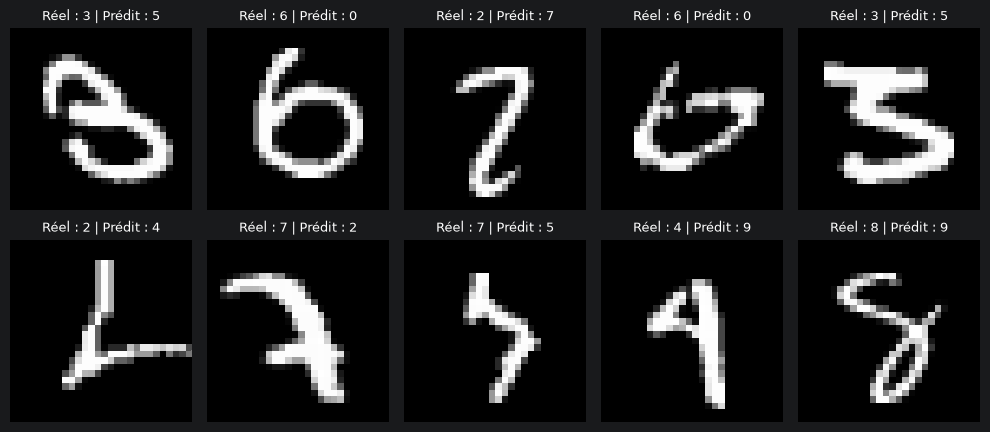

In [67]:
def afficher_erreurs(preds, n=10):
    # Affiche les n premières images du test mal classées, avec vraie classe et prédiction
    erreurs = (preds != y_test).nonzero(as_tuple=True)[0]
    print(f"Nombre d'images mal classées : {len(erreurs)} sur {len(y_test)}")

    n = min(n, len(erreurs))
    fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))

    for ax, idx in zip(axes.flatten(), erreurs[:n].tolist()):
        image, label = test_dataset[idx]
        image = image[0] * 0.3081 + 0.1307
        ax.imshow(image.numpy(), cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"Réel : {label} | Prédit : {preds[idx].item()}", fontsize=9)
        ax.axis("off")

    for ax in axes.flatten()[n:]:      # cases vides s'il y a moins de 10 erreurs
        ax.axis("off")

    plt.tight_layout()
    plt.show()

afficher_erreurs(preds)

### Ajouter un Dropout avant la dernière couche linéaire

Le Dropout met à zéro au hasard une partie des neurones pendant l'entraînement (ici 30 %), ce qui limite le surapprentissage.
Il n'agit qu'en mode `train()` : en `eval()` toutes les valeurs passent.

In [68]:
torch.manual_seed(42)
model_dropout = MNISTClassifier(dropout=0.3).to(device)

t0 = time.perf_counter()
loss_history_dropout = entrainer(model_dropout, epochs=epochs)
temps_dropout = time.perf_counter() - t0

preds_dropout, _ = evaluer(model_dropout)
accuracy_dropout = (preds_dropout == y_test).float().mean().item()
print(f"Accuracy CNN + Dropout : {accuracy_dropout:.2%}")

Époque 1/3 | Perte : 0.2055
Époque 2/3 | Perte : 0.0683
Époque 3/3 | Perte : 0.0501
Accuracy CNN + Dropout : 98.85%


### Sauvegarder les paramètres

On sauvegarde le `state_dict`, puis on le recharge dans un réseau neuf de même architecture.

In [69]:
torch.save(model.state_dict(), "mnist_cnn.pth")
print("Paramètres sauvegardés dans mnist_cnn.pth")

model_recharge = MNISTClassifier().to(device)
model_recharge.load_state_dict(torch.load("mnist_cnn.pth", weights_only=True, map_location=device))

preds_recharge, _ = evaluer(model_recharge)
print(f"Accuracy du modèle rechargé : {(preds_recharge == y_test).float().mean().item():.2%}")
print("Prédictions identiques :", torch.equal(preds, preds_recharge))

Paramètres sauvegardés dans mnist_cnn.pth
Accuracy du modèle rechargé : 98.88%
Prédictions identiques : True


## 7. Comparaison avec le MLP de l'Exercice 3

Même jeu de données, même nombre d'époques, même optimiseur, seul le réseau change.

In [70]:
torch.manual_seed(42)
mlp = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
).to(device)

t0 = time.perf_counter()
loss_history_mlp = entrainer(mlp, epochs=epochs)
temps_mlp = time.perf_counter() - t0

preds_mlp, _ = evaluer(mlp)

resultats = [
    ("MLP",           mlp,           loss_history_mlp,     preds_mlp,     temps_mlp),
    ("CNN",           model,         loss_history,         preds,         temps_cnn),
    ("CNN + Dropout", model_dropout, loss_history_dropout, preds_dropout, temps_dropout),
]

print(f"{'Modèle':<15s} {'Paramètres':>11s} {'Perte finale':>13s} {'Accuracy test':>14s} {'Erreurs':>8s} {'Temps':>8s}")
for nom, m, hist, p, t in resultats:
    n_params = sum(q.numel() for q in m.parameters())
    acc = (p == y_test).float().mean().item()
    n_err = (p != y_test).sum().item()
    print(f"{nom:<15s} {n_params:>11,d} {hist[-1]:>13.4f} {acc:>14.2%} {n_err:>8d} {t:>7.1f}s")

Époque 1/3 | Perte : 0.2585
Époque 2/3 | Perte : 0.1125
Époque 3/3 | Perte : 0.0765
Modèle           Paramètres  Perte finale  Accuracy test  Erreurs    Temps
MLP                 101,770        0.0765         97.65%      235    38.3s
CNN                 206,922        0.0348         98.88%      112    85.6s
CNN + Dropout       206,922        0.0501         98.85%      115    85.7s


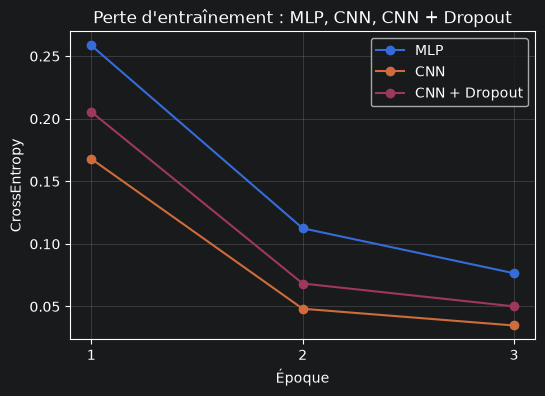

In [71]:
plt.figure(figsize=(6, 4))
for nom, _, hist, _, _ in resultats:
    plt.plot(range(1, epochs + 1), hist, marker="o", label=nom)
plt.xlabel("Époque")
plt.ylabel("CrossEntropy")
plt.title("Perte d'entraînement : MLP, CNN, CNN + Dropout")
plt.xticks(range(1, epochs + 1))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()